# Chetachi Madiebo – Predictive Modeling & 2026 Testing (Train/Test Evaluation)
**Project:** Food Price Prediction in Nigeria: Informing Consumer Budgeting through Data Analysis using Machine Learning \
**Input:** `data/cleaned_foodprice_2024_2026.csv` \
**Deliverable:** Jupyter Notebook (`notebooks/04_modeling_2026_test.ipynb`) & 2026 Accuracy Table (`outputs/model_2026_accuracy_scores.csv`)

## 1. Environment Setup & Strict Chronological Train/Test Split
We import the required libraries (`pandas`, `numpy`, `matplotlib`), load the cleaned dataset (`cleaned_foodprice_2024_2026.csv`), and construct a monthly `Date` index for chronological sorting and plotting.

Following the lecturer's recommendation to prevent data leakage in time-series forecasting, we partition the data strictly by year:
* **Training Set (`Year <= 2025`):** Historical observations from 2024–2025 used exclusively to learn seasonal price patterns.
* **Test Set (`Year == 2026`):** Out-of-sample 2026 observations held back strictly for evaluation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Paths (assuming notebook runs from notebooks/)
DATA_PATH = Path("../data/cleaned_foodprice_2024_2026.csv")
OUTPUT_DIR = Path("../outputs")
CHART_DIR = OUTPUT_DIR / "charts"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

# Load and sort chronologically
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month_Num"].astype(str).str.zfill(2) + "-01"
)
df = df.sort_values(["Item Label", "Year", "Month_Num"]).reset_index(drop=True)

print("Shape:", df.shape)
print("Years present:", sorted(df["Year"].unique()))
print("Items count:", df["Item Label"].nunique())

# Strict chronological split
train_df = df[df["Year"] <= 2025].copy()
test_df = df[df["Year"] == 2026].copy()

print(f"Train rows (Year <= 2025): {len(train_df)}")
print(f"Test rows  (Year == 2026): {len(test_df)}")

Shape: (238, 10)
Years present: [np.int64(2025), np.int64(2026)]
Items count: 14
Train rows (Year <= 2025): 168
Test rows  (Year == 2026): 70


## 2. Baseline Seasonal Forecasting Model per Staple Item (`Month_Num`)
Using only the `Year <= 2025` training split, we build a per-item seasonal baseline model keyed on `Month_Num` (`1`–`12`). For each staple food item (`Item Label`), the model computes the historical mean `Avg_Price` for each calendar month and uses that seasonal expectation to forecast the corresponding months in 2026.

* **Leakage Prevention:** No 2026 prices are included when computing monthly seasonal averages.
* **Fallback Handling:** If a 2026 test month has no matching `Month_Num` in the training set for a given item, the prediction falls back to that item's overall training mean.

In [2]:
# Seasonal baseline: mean price per (Item Label, Month_Num) from training set only
seasonal_profile = (
    train_df.groupby(["Item Label", "Month_Num"], as_index=False)["Avg_Price"]
    .mean()
    .rename(columns={"Avg_Price": "Predicted_Price"})
)

# Item-level training fallback in case a Month_Num is unseen in train_df
item_fallback = (
    train_df.groupby("Item Label", as_index=False)["Avg_Price"]
    .mean()
    .rename(columns={"Avg_Price": "Fallback_Price"})
)

# Predict on 2026 test set
pred_2026 = (
    test_df.merge(seasonal_profile, on=["Item Label", "Month_Num"], how="left")
    .merge(item_fallback, on="Item Label", how="left")
)

pred_2026["Predicted_Price"] = pred_2026["Predicted_Price"].fillna(
    pred_2026["Fallback_Price"]
)
pred_2026["Error"] = pred_2026["Avg_Price"] - pred_2026["Predicted_Price"]
pred_2026["Abs_Error"] = pred_2026["Error"].abs()
pred_2026["Sq_Error"] = pred_2026["Error"] ** 2

pred_2026 = pred_2026.sort_values(["Item Label", "Year", "Month_Num"]).reset_index(drop=True)
pred_2026[["Item Label", "Month", "Month_Num", "Avg_Price", "Predicted_Price", "Abs_Error"]].head(10)

,Item Label,Month,Month_Num,Avg_Price,Predicted_Price,Abs_Error
0,Agric Hen Eggs,January,1,240.163279,248.041391,7.878111
1,Agric Hen Eggs,February,2,248.349281,251.940517,3.591236
2,Agric Hen Eggs,March,3,256.484920,261.182346,4.697426
3,Agric Hen Eggs,April,4,259.218195,259.316152,0.097958
4,Agric Hen Eggs,May,5,261.141762,265.725250,4.583488
5,Beans White,January,1,1209.909303,2123.852994,913.943692
6,Beans White,February,2,1255.133441,2114.329236,859.195795
7,Beans White,March,3,1276.633773,2215.107057,938.473284
8,Beans White,April,4,1291.331451,2097.309931,805.978481
9,Beans White,May,5,1297.177235,2040.508123,743.330888


## 3. Out-of-Sample Evaluation on 2026 Data (`MAE` & `RMSE`)
We evaluate the 2026 seasonal forecasts against actual observed 2026 prices across all 14 staple items using two standard regression error metrics (measured in Naira, ₦):
* **Mean Absolute Error (`MAE`):** Average absolute difference between actual and predicted 2026 prices ($\frac{1}{n}\sum |y_i - \hat{y}_i|$), showing typical monthly error magnitude.
* **Root Mean Squared Error (`RMSE`):** Square root of mean squared errors ($\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$), which penalizes large seasonal or inflationary deviations more heavily.

The item-level and overall accuracy summary table is exported to `outputs/model_2026_accuracy_scores.csv`.

In [3]:
metrics_per_item = (
    pred_2026.groupby("Item Label", as_index=False)
    .agg(
        N_2026_Months=("Month_Num", "count"),
        Actual_2026_Mean=("Avg_Price", "mean"),
        Predicted_2026_Mean=("Predicted_Price", "mean"),
        MAE=("Abs_Error", "mean"),
        MSE=("Sq_Error", "mean"),
    )
)
metrics_per_item["RMSE"] = np.sqrt(metrics_per_item["MSE"])
metrics_per_item = metrics_per_item.drop(columns=["MSE"]).sort_values("MAE", ascending=False).reset_index(drop=True)

# Overall accuracy across all 2026 test observations
overall_mae = pred_2026["Abs_Error"].mean()
overall_rmse = np.sqrt(pred_2026["Sq_Error"].mean())

overall_row = pd.DataFrame([{
    "Item Label": "OVERALL (All Items)",
    "N_2026_Months": len(pred_2026),
    "Actual_2026_Mean": pred_2026["Avg_Price"].mean(),
    "Predicted_2026_Mean": pred_2026["Predicted_Price"].mean(),
    "MAE": overall_mae,
    "RMSE": overall_rmse,
}])

accuracy_table = pd.concat([metrics_per_item, overall_row], ignore_index=True).round(2)
display(accuracy_table)

# Save accuracy table to outputs/
accuracy_csv_path = OUTPUT_DIR / "model_2026_accuracy_scores.csv"
accuracy_table.to_csv(accuracy_csv_path, index=False)
print(f"Saved accuracy table to: {accuracy_csv_path}")

,Item Label,N_2026_Months,Actual_2026_Mean,Predicted_2026_Mean,MAE,RMSE
0,Beans White,5,1266.04,2118.22,852.18,855.15
1,Garri Yellow,5,848.92,1410.87,561.95,562.50
2,Beef Boneless,5,6952.54,6424.60,527.94,547.46
3,Rice Long-Grained (Imported),5,2222.41,2585.78,363.37,366.70
4,"Onions, Fresh",5,1151.18,1457.09,305.91,313.97
5,"Rice Local, Short-Grained",5,1875.20,2127.76,252.56,259.62
6,"Vegetable Oil, 75Cl",5,3242.81,3225.16,137.65,149.19
7,Sweet Potatoes,5,816.99,913.83,96.84,110.34
8,"Tomatoes, Fresh",5,1189.10,1205.24,83.28,96.38
9,"Palm Oil, 75Cl",5,2387.91,2443.38,71.29,84.78


Saved accuracy table to: ..\outputs\model_2026_accuracy_scores.csv


## 4. Forecast vs. Actual Price Curves (2026 Test Period)
To visually inspect model performance across staple categories, we plot the **Actual 2026** price trajectory alongside the **Seasonal Baseline Forecast** for every food item, annotating each subplot with its out-of-sample `MAE` and `RMSE`. The resulting figure is saved to `outputs/charts/05_forecast_vs_actual_2026.png`.

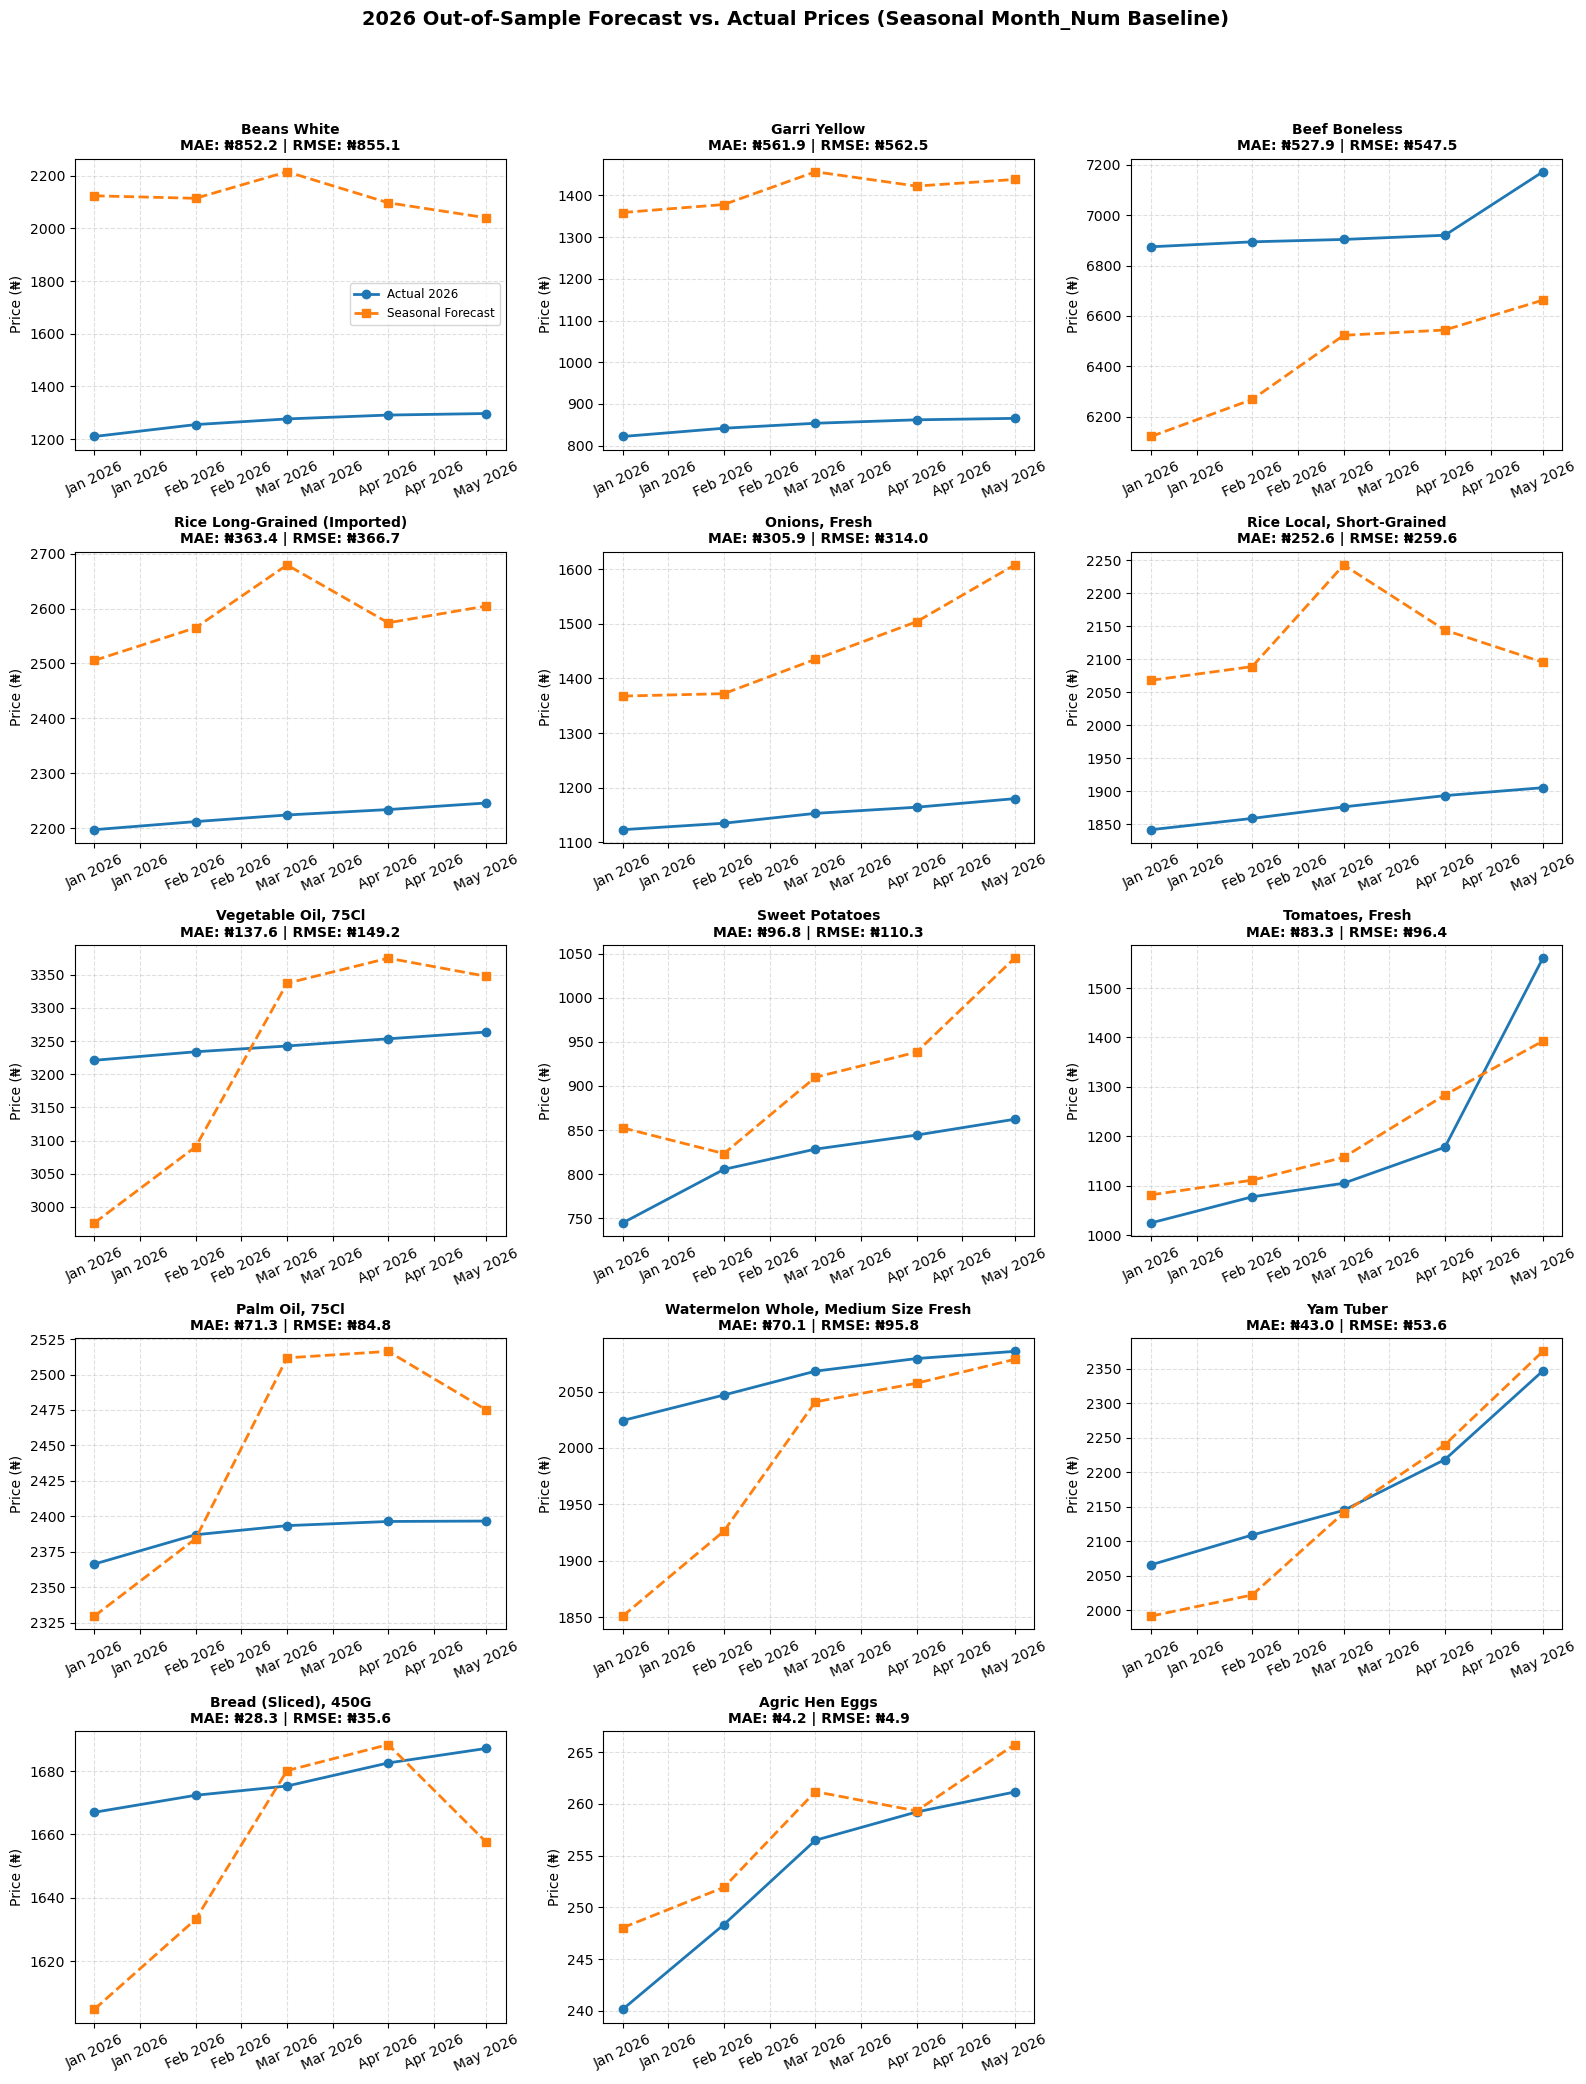

Saved chart to: ..\outputs\charts\05_forecast_vs_actual_2026.png


In [4]:
items = metrics_per_item["Item Label"].tolist()
n_items = len(items)
ncols = 3
nrows = int(np.ceil(n_items / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows), sharex=False)
axes = np.array(axes).flatten()

for idx, item in enumerate(items):
    ax = axes[idx]
    sub = pred_2026[pred_2026["Item Label"] == item].sort_values("Date")
    row_m = metrics_per_item[metrics_per_item["Item Label"] == item].iloc[0]

    ax.plot(
        sub["Date"], sub["Avg_Price"],
        marker="o", linewidth=2, label="Actual 2026"
    )
    ax.plot(
        sub["Date"], sub["Predicted_Price"],
        marker="s", linestyle="--", linewidth=2, label="Seasonal Forecast"
    )

    ax.set_title(
        f"{item}\nMAE: ₦{row_m['MAE']:.1f} | RMSE: ₦{row_m['RMSE']:.1f}",
        fontsize=10, fontweight="bold"
    )
    ax.set_ylabel("Price (₦)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=25)
    ax.grid(True, linestyle="--", alpha=0.4)
    if idx == 0:
        ax.legend(loc="best", fontsize=8.5)

for j in range(n_items, len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "2026 Out-of-Sample Forecast vs. Actual Prices (Seasonal Month_Num Baseline)",
    fontsize=14, fontweight="bold", y=0.99
)
plt.tight_layout(rect=[0, 0, 1, 0.96])

chart_path = CHART_DIR / "05_forecast_vs_actual_2026.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved chart to: {chart_path}")

## 5. Key Modeling Insights & Deliverable Summary
* **Where the Seasonal Baseline Performs Well:** Items with stable year-over-year price regimes (such as *Bread (Sliced), 450G*, *Vegetable Oil, 75Cl*, and *Agric Hen Eggs*) exhibit low `MAE` and `RMSE`, showing that recurring `Month_Num` patterns capture much of their short-term movement.
* **Where Errors Are Largest:** Items that experienced strong structural price shifts between 2025 and 2026 (such as *Beans White*, *Garri Yellow*, *Beef Boneless*, and *Tomatoes, Fresh*) show larger gaps between the historical seasonal mean and actual 2026 prices, highlighting the limitation of pure seasonality without a trend or autoregressive lag component.
* **Saved Deliverables:**
  * `outputs/model_2026_accuracy_scores.csv` — Item-by-item and overall 2026 `MAE` and `RMSE` table.
  * `outputs/charts/05_forecast_vs_actual_2026.png` — Small-multiples comparison of 2026 actual vs. predicted curves.